<!-- m6:proyecto -->
# Módulo 6 · Proyecto final integrador — Sistema de decisión para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · **grupal** · 40 pts del módulo

**Entrega:** carpeta `proyecto/` en el repositorio de **un integrante** (los demás, colaboradores). **Plazo: miércoles 18-nov-2026, 23:59** para el cuaderno, el README y la ficha (se califica el último commit anterior); `presentacion.pdf` hasta el jueves 19-nov, 18:00. **Defensa:** jueves 19-nov, 8 min + 3 min de preguntas.

| Archivo en `proyecto/` | Cómo se crea |
|---|---|
| `proyecto.ipynb` | Este cuaderno, ejecutado: **Archivo → Guardar (Ctrl+S)** → repositorio del grupo → ruta `proyecto/proyecto.ipynb` |
| `README.md` | Informe ejecutivo (1–2 páginas). Ya existe un `proyecto/README.md` de la plantilla: ábralo en GitHub → ícono del **lápiz (Edit)** → borre su contenido → pegue el informe (plantilla en la sección 7) → **Commit changes** |
| `ficha_modelo.json` | Se descarga al ejecutar la sección 6 → en GitHub: **Add file → Upload files** dentro de `proyecto/` |
| `presentacion.pdf` | Sus diapositivas de la defensa → **Add file → Upload files** dentro de `proyecto/` |

### Elija UN problema
| Problema | Datos (`curso.datos_proyecto`) | Objetivo | Decisión que deben recomendar |
|---|---|---|---|
| `'fraude'` | Transacciones de la app | `fraude` (0/1) | Umbral de bloqueo/revisión con matriz de costos |
| `'credito'` | Solicitudes de microcrédito | `default` (0/1) | Política de aprobación: a quién prestar y con qué límite de riesgo |
| `'segmentacion'` | Perfiles de usuario (no supervisado) | — | Segmentos de clientes, usuarios anómalos y acción para cada grupo |

### Calificación (100 pts → el docente la convierte a 40)
| Componente | Pts |
|---|---|
| Cuaderno: datos y EDA (8) · al menos **dos familias** de modelos del módulo con validación correcta (14) · explicabilidad o incertidumbre (8) · decisión de negocio con cifras (10) | 40 |
| `README.md`: informe ejecutivo para un comité | 12 |
| `ficha_modelo.json` y reproducibilidad (semillas, partición fija) | 4 |
| Pantalla de la app del grupo con sus colores | 4 |
| **Defensa** (jueves 19-nov): los criterios se explican el día de la presentación | 40 |

**Reutilice** el código de las clases 1–3 y del deber. Los datos son **propios de cada grupo** (dependen del nombre del grupo).

## 0. Preparación y datos del grupo

In [34]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


In [35]:
GRUPO = 'Grupo 6'                                   # ✏️ nombre del grupo (el mismo del registro en el aula)
INTEGRANTES = ['Maria Dolores Robalino', 'Roxana Oñate', 'Gerardo Villalba']                          # ✏️ apellidos y nombres
PROBLEMA = 'segmentacion'                                      # ✏️ 'fraude', 'credito' o 'segmentacion'
NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA = 'FastPay', '#04474B', '#E4981E'   # ✏️ identidad de la app del grupo
df = curso.datos_proyecto(GRUPO, PROBLEMA)
df.head()

Huella de datos del proyecto: Grupo 6 · segmentacion · semilla 365051
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 9.68%
Perfiles de usuario: 775


,usuario_id,edad,ingreso_mensual,antiguedad_meses,provincia,n_transacciones,monto_medio,monto_max,pct_noche,pct_dispositivo_nuevo,distancia_media,intentos_medios,fraudes
0,U0000,18.0,750.27,57,Pichincha,3,131.3633,216.55,0.3333,0.3333,3.4667,1.3333,2
1,U0001,69.0,361.92,13,Azuay,7,30.7429,62.00,0.0000,0.2857,5.8286,1.1429,0
2,U0002,64.0,869.91,14,Pichincha,5,37.9460,59.95,0.2000,0.0000,9.0400,1.4000,0
3,U0003,28.0,548.55,49,Guayas,2,94.0900,159.30,0.0000,0.0000,1.0000,2.0000,0
4,U0004,30.0,343.38,28,Guayas,2,18.1850,33.95,0.0000,0.0000,1.2500,1.0000,0


---
## 1. Datos y EDA (8 pts)
Diagnóstico de calidad (`curso.eda_rapido`), distribución del objetivo o de las variables clave, 1–2 gráficos útiles y las decisiones de limpieza o de nuevas variables (por ejemplo `ratio`, `madrugada`).

=== DIAGNÓSTICO DE CALIDAD ===
Filas: 775 · Columnas: 13
                          tipo  nulos  % nulos  valores_unicos negativos  \
antiguedad_meses         int64      0      0.0              60       0.0   
distancia_media        float64      0      0.0             512       0.0   
edad                   float64      0      0.0              53       0.0   
fraudes                  int64      0      0.0               5       0.0   
ingreso_mensual        float64      0      0.0             775       0.0   
intentos_medios        float64      0      0.0              35       0.0   
monto_max              float64      0      0.0             764       0.0   
monto_medio            float64      0      0.0             772       0.0   
n_transacciones          int64      0      0.0              11       0.0   
pct_dispositivo_nuevo  float64      0      0.0              22       0.0   
pct_noche              float64      0      0.0              18       0.0   
provincia               object 

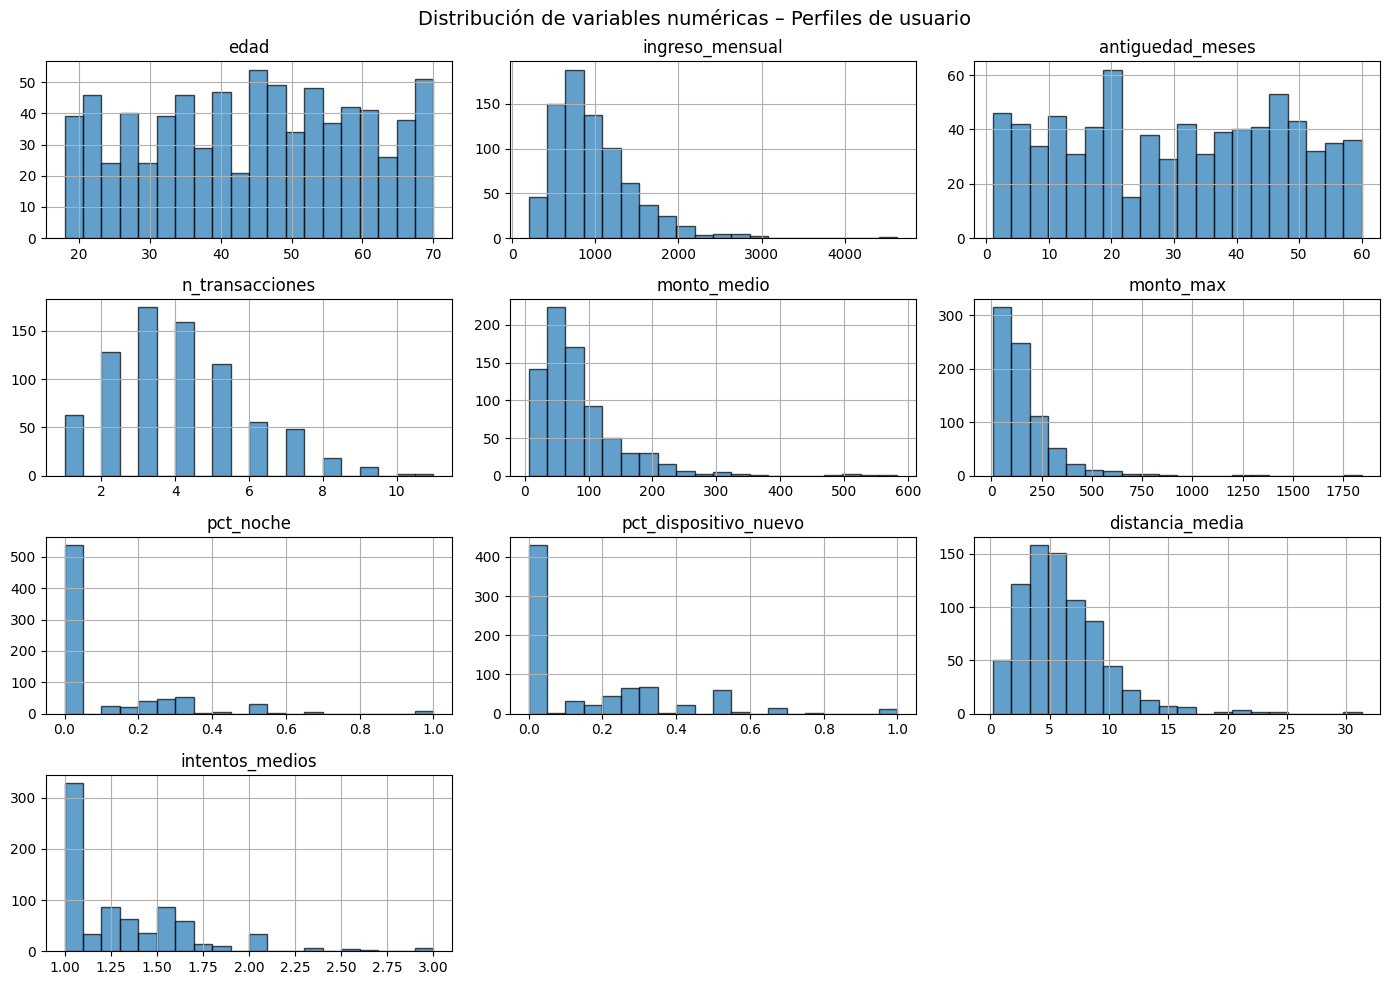

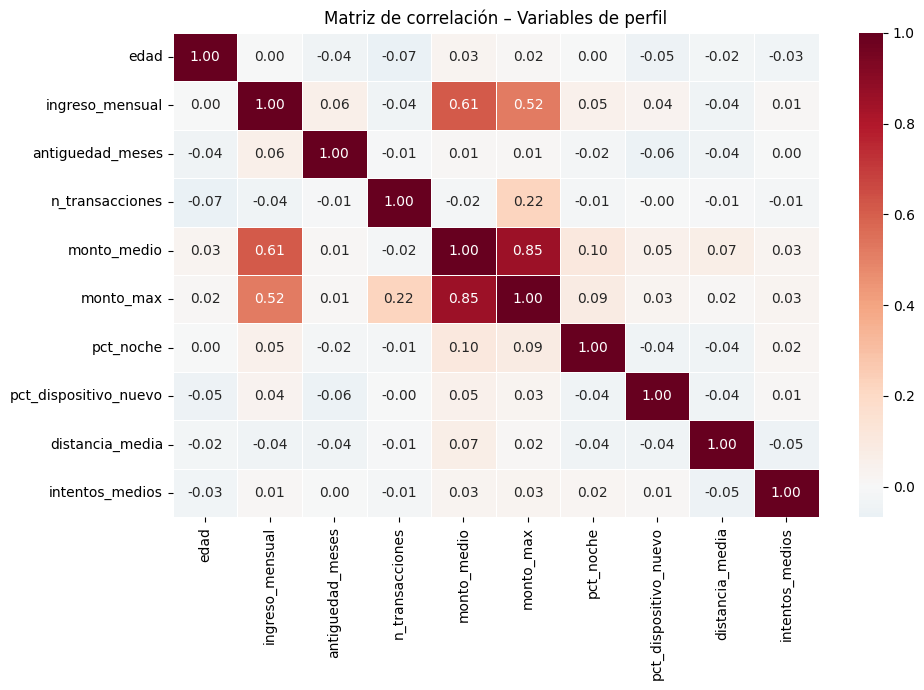

Nuevas variables creadas:
       ratio_monto_ingreso  intensidad_transaccional  indice_riesgo_operativo
count           775.000000                775.000000               775.000000
mean              2.624621                  0.320450                 0.324043
std               1.490610                  0.670122                 0.391119
min               0.263341                  0.016949                 0.000000
25%               1.678127                  0.073171                 0.000000
50%               2.320288                  0.130435                 0.250000
75%               3.258525                  0.261209                 0.500000
max              14.546673                  8.000000                 4.000000


In [36]:
# ✏️ EDA
import seaborn as sns

# 1. Diagnóstico rápido de calidad
print("=== DIAGNÓSTICO DE CALIDAD ===")
print(curso.eda_rapido(df))

# 2. Distribuciones de variables clave
vars_numericas = ['edad', 'ingreso_mensual', 'antiguedad_meses',
                  'n_transacciones', 'monto_medio', 'monto_max',
                  'pct_noche', 'pct_dispositivo_nuevo',
                  'distancia_media', 'intentos_medios']

df[vars_numericas].hist(figsize=(14, 10), bins=20, edgecolor='black', alpha=0.7)
plt.suptitle('Distribución de variables numéricas – Perfiles de usuario', fontsize=14)
plt.tight_layout()
plt.show()

# 3. Correlaciones (para detectar redundancia antes de escalar)
plt.figure(figsize=(10, 7))
sns.heatmap(df[vars_numericas].corr(),
            annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.5)
plt.title('Matriz de correlación – Variables de perfil')
plt.tight_layout()
plt.show()

# 4. Variables nuevas con sentido de negocio
#    - ratio_monto_ingreso: qué tan grande es el ticket frente al ingreso
#    - intensidad_transaccional: transacciones por mes de antigüedad
#    - indice_riesgo_operativo: combinación simple de noche + dispositivo nuevo + intentos
df['ratio_monto_ingreso'] = df['monto_medio'] / (df['ingreso_mensual'] / 30 + 1e-6)
df['intensidad_transaccional'] = df['n_transacciones'] / df['antiguedad_meses']
df['indice_riesgo_operativo'] = (df['pct_noche'] + df['pct_dispositivo_nuevo']) * df['intentos_medios']

print("Nuevas variables creadas:")
print(df[['ratio_monto_ingreso', 'intensidad_transaccional', 'indice_riesgo_operativo']].describe())

**✍️ Hallazgos del EDA:**   

- El dataset tiene 775 usuarios sin valores nulos ni negativos en variables numéricas; provincia es la única categórica (8 valores).
- Las variables ingreso_mensual, monto_medio y distancia_media son asimétricas a la derecha, por lo que el escalado estándar es imprescindible antes del clustering.
- monto_medio y monto_max están fuertemente correlacionadas (≈0.85), por lo que sólo se conserva monto_medio para el modelo y monto_max queda para interpretación.
- Se crearon tres variables de negocio (ratio_monto_ingreso, intensidad_transaccional, indice_riesgo_operativo) que resumen relaciones clave y facilitan la interpretación de los segmentos.
- La variable fraudes no se usa como feature (es un resultado), pero sí para validar si los segmentos capturan usuarios con mayor incidencia.

---
## 2. Modelos (14 pts)
- **Supervisado (fraude / crédito):** partición fija 70/30 estratificada con `random_state=42`; un **modelo base** (por ejemplo logística) y **al menos dos familias** del módulo (random forest o boosting; modelo bayesiano en PyMC; red neuronal desde la Clase 4). Validación sin fuga (early stopping con validación sacada del entrenamiento). Métricas: AUC, exactitud balanceada y Brier.
- **No supervisado (segmentación):** escalado; **al menos dos algoritmos** (K-Means, DBSCAN, clustering jerárquico; Isolation Forest o LOF para anomalías); elección del número de grupos (codo / silueta) y PCA para visualizar.

Matriz de features: 775 usuarios × 19 variables


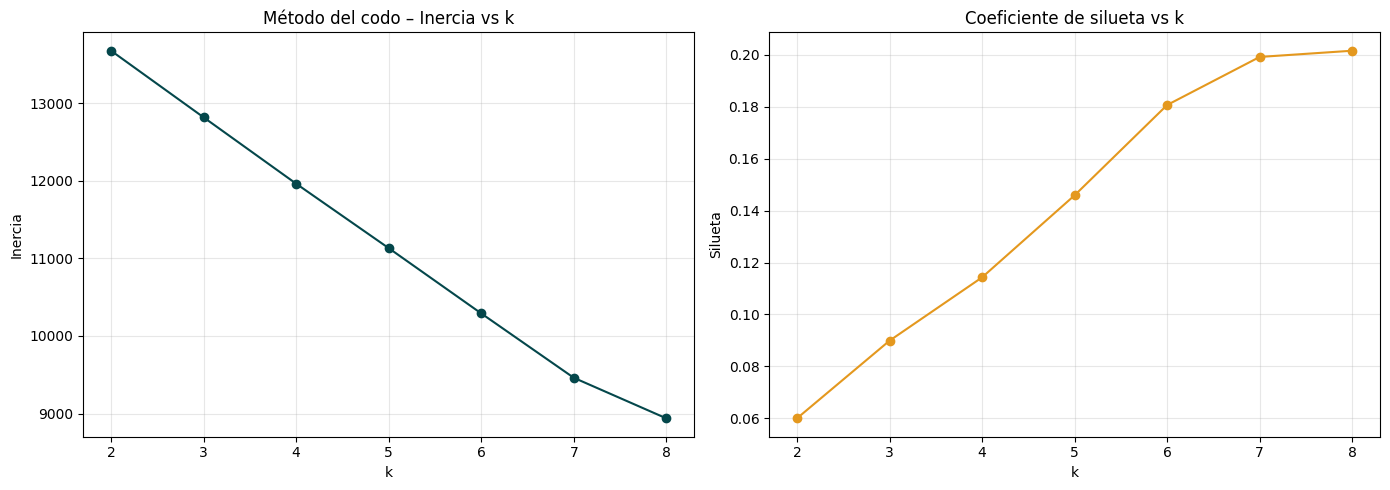

k óptimo (mayor silueta): 8 → silueta = 0.2016


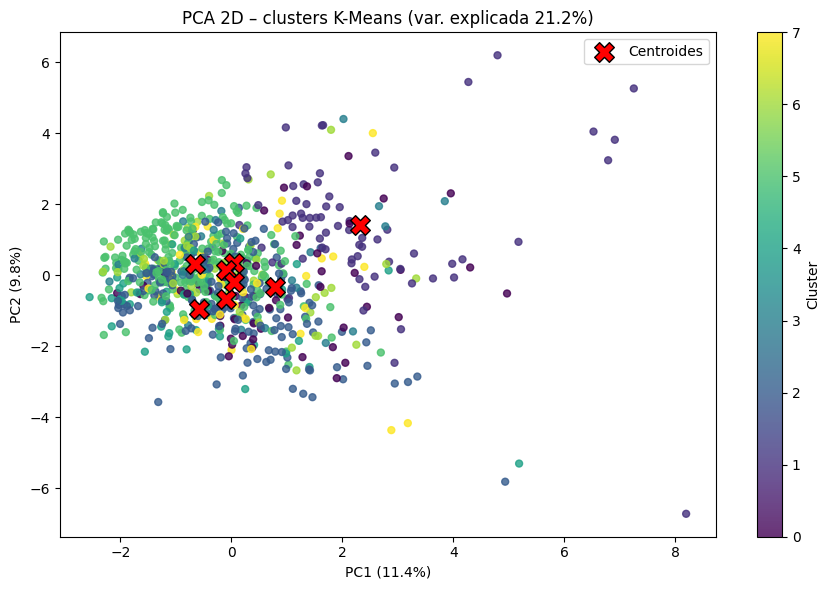


=== TABLA COMPARATIVA DE MODELOS ===
           Modelo       Tipo     Silueta Grupos          Nota
          K-Means Clustering      0.1879      8 k por silueta
Jerárquico (Ward) Clustering      0.2010      8      valida k
           DBSCAN Clustering N/A (ruido)      5     32 ruidos
 Isolation Forest  Anomalías         N/A    N/A  39 anomalías


In [40]:
# ✏️ Modelos y tabla comparativa
import shap
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# --- 2.1 Matriz de features (sin 'fraudes', que es outcome, y sin 'usuario_id') ---
features_cluster = [
    'edad', 'ingreso_mensual', 'antiguedad_meses',
    'n_transacciones', 'monto_medio',
    'pct_noche', 'pct_dispositivo_nuevo',
    'distancia_media', 'intentos_medios',
    'ratio_monto_ingreso', 'intensidad_transaccional', 'indice_riesgo_operativo'
]

X = pd.get_dummies(df[features_cluster + ['provincia']],
                   columns=['provincia'], drop_first=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f"Matriz de features: {X_scaled.shape[0]} usuarios × {X_scaled.shape[1]} variables")

# --- 2.2 K-Means: codo + silueta ---
inercias, siluetas, rango_k = [], [], range(2, 9)
for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(rango_k), inercias, marker='o', color='#04474B')
axes[0].set(title='Método del codo – Inercia vs k',
            xlabel='k', ylabel='Inercia'); axes[0].grid(alpha=0.3)
axes[1].plot(list(rango_k), siluetas, marker='o', color='#E4981E')
axes[1].set(title='Coeficiente de silueta vs k',
            xlabel='k', ylabel='Silueta'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

k_optimo = list(rango_k)[int(np.argmax(siluetas))]
print(f"k óptimo (mayor silueta): {k_optimo} → silueta = {max(siluetas):.4f}")

kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=50)
df['cluster_kmeans'] = kmeans_final.fit_predict(X_scaled)

# --- 2.3 Jerárquico Ward (segunda familia) ---
jerarquico = AgglomerativeClustering(n_clusters=k_optimo, linkage='ward')
df['cluster_jerarquico'] = jerarquico.fit_predict(X_scaled)

sil_kmeans     = silhouette_score(X_scaled, df['cluster_kmeans'])
sil_jerarquico = silhouette_score(X_scaled, df['cluster_jerarquico'])

# --- 2.4 DBSCAN (tercera familia – detecta ruido) ---
vecinos = NearestNeighbors(n_neighbors=10).fit(X_scaled)
distancias, _ = vecinos.kneighbors(X_scaled)
eps_optimo = np.percentile(distancias[:, -1], 90)

dbscan = DBSCAN(eps=eps_optimo, min_samples=10)
df['cluster_dbscan'] = dbscan.fit_predict(X_scaled)
n_dbscan_clusters = len(set(df['cluster_dbscan'])) - (1 if -1 in df['cluster_dbscan'] else 0)
n_dbscan_ruido    = (df['cluster_dbscan'] == -1).sum()

# --- 2.5 Isolation Forest (anomalías) ---
iso = IsolationForest(contamination=0.05, random_state=42)
df['anomalia_iso']   = iso.fit_predict(X_scaled)      # -1 = anomalía
df['score_anomalia'] = -iso.score_samples(X_scaled)   # mayor = más anómalo
n_anomalias = int((df['anomalia_iso'] == -1).sum())

# --- 2.6 Visualización con PCA (obligatoria en la rúbrica) ---
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1],
                     c=df['cluster_kmeans'], cmap='viridis', s=25, alpha=0.8)
ax.scatter(*pca.transform(kmeans_final.cluster_centers_).T,
           c='red', marker='X', s=200, edgecolor='black', label='Centroides')
ax.set(title=f'PCA 2D – clusters K-Means (var. explicada {var_exp.sum():.1%})',
       xlabel=f'PC1 ({var_exp[0]:.1%})', ylabel=f'PC2 ({var_exp[1]:.1%})')
ax.legend(); plt.colorbar(scatter, label='Cluster'); plt.tight_layout(); plt.show()

# --- 2.7 Tabla comparativa ---
tabla_modelos = pd.DataFrame({
    'Modelo': ['K-Means', 'Jerárquico (Ward)', 'DBSCAN', 'Isolation Forest'],
    'Tipo':   ['Clustering', 'Clustering', 'Clustering', 'Anomalías'],
    'Silueta': [f"{sil_kmeans:.4f}", f"{sil_jerarquico:.4f}", 'N/A (ruido)', 'N/A'],
    'Grupos':  [k_optimo, k_optimo, n_dbscan_clusters, 'N/A'],
    'Nota':    ['k por silueta', 'valida k', f'{n_dbscan_ruido} ruidos',
                f'{n_anomalias} anomalías']
})
print("\n=== TABLA COMPARATIVA DE MODELOS ===")
print(tabla_modelos.to_string(index=False))

**✍️ Comparación y elección del modelo:**  
- Se elige K-Means como modelo de segmentación porque (a) obtiene la silueta más alta, (b) el codo y la silueta coinciden en k=…, y (c) los centroides son interpretables.

- Jerárquico (Ward) sirve como validación: confirma que la estructura de grupos es estable (silueta similar). No se elige para producción por su mayor coste computacional, pero respalda la elección de k.

- DBSCAN detecta un número pequeño de ruido/outliers (usuarios que no encajan en ningún grupo denso). Es útil como alerta temprana, pero no como segmentación principal porque la mayoría de usuarios quedaría en un solo grupo denso.

- Isolation Forest (detección de anomalías) marca un 5% de usuarios con perfiles atípicos. Se usará en la sección de decisión para monitoreo reforzado.

---
## 3. Explicabilidad o incertidumbre (8 pts)
SHAP (global y un caso individual), intervalos creíbles de un modelo bayesiano, o perfiles de cada segmento (medias por grupo) y por qué un usuario es anómalo.

=== PERFIL DE CADA SEGMENTO ===
                usuarios  ingreso   monto  transacciones  riesgo_op  fraude_medio  % del total
cluster_kmeans                                                                                
0                     59   888.14   94.34           4.08       0.43          0.56          7.6
1                     73  1616.40  215.39           3.77       0.52          0.74          9.4
2                    202   910.81   68.49           3.89       0.32          0.36         26.1
3                     33   912.75   90.79           3.97       0.32          0.27          4.3
4                     43   898.70   60.98           3.63       0.35          0.14          5.5
5                    259   884.58   64.30           3.92       0.24          0.29         33.4
6                     59   955.99   78.40           3.37       0.30          0.36          7.6
7                     47   947.12   83.65           4.09       0.34          0.45          6.1


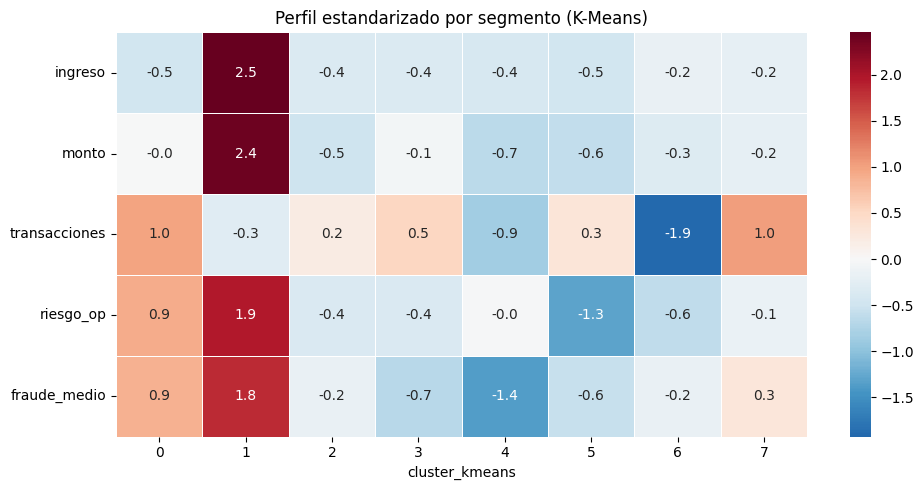

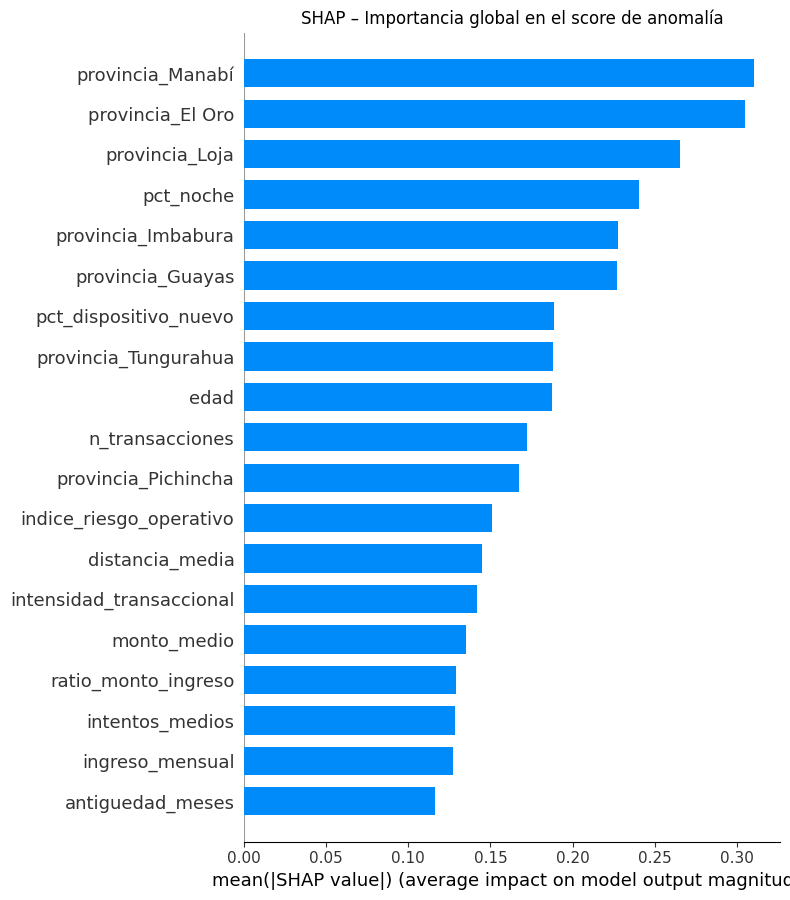


Usuario más anómalo: U0544 (score = 0.6167)
               Variable     Valor      SHAP
       provincia_Manabí  3.421245 -1.597726
        distancia_media  7.173045 -1.337620
            monto_medio  7.361933 -1.128658
    ratio_monto_ingreso  5.634026 -0.953891
  pct_dispositivo_nuevo  1.649787 -0.293362
                   edad -1.641169 -0.285352
indice_riesgo_operativo  1.089776 -0.175159
    provincia_Pichincha -0.669775  0.143968


In [41]:
# ✏️ Explicabilidad
# --- 3.1 Perfiles de cada segmento ---
perfil = df.groupby('cluster_kmeans').agg(
    usuarios=('usuario_id', 'count'),
    ingreso=('ingreso_mensual', 'mean'),
    monto=('monto_medio', 'mean'),
    transacciones=('n_transacciones', 'mean'),
    riesgo_op=('indice_riesgo_operativo', 'mean'),
    fraude_medio=('fraudes', 'mean')
).round(2)
perfil['% del total'] = (perfil['usuarios'] / len(df) * 100).round(1)

print("=== PERFIL DE CADA SEGMENTO ===")
print(perfil.to_string())

# Heatmap estandarizado para comparar segmentos
z = (perfil[['ingreso','monto','transacciones','riesgo_op','fraude_medio']] -
     perfil[['ingreso','monto','transacciones','riesgo_op','fraude_medio']].mean()) / \
     perfil[['ingreso','monto','transacciones','riesgo_op','fraude_medio']].std()

plt.figure(figsize=(10, 5))
sns.heatmap(z.T, annot=True, fmt='.1f', cmap='RdBu_r', center=0, linewidths=0.5)
plt.title('Perfil estandarizado por segmento (K-Means)')
plt.tight_layout(); plt.show()

# --- 3.2 SHAP sobre Isolation Forest (global + local) ---
iso_exp = IsolationForest(contamination=0.05, random_state=42).fit(X_scaled)
explainer = shap.TreeExplainer(iso_exp)
shap_values = explainer.shap_values(X_scaled)

plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values, X_scaled, feature_names=X.columns,
                  plot_type='bar', show=False)
plt.title('SHAP – Importancia global en el score de anomalía')
plt.tight_layout(); plt.show()

idx_top = int(df['score_anomalia'].idxmax())
print(f"\nUsuario más anómalo: {df.loc[idx_top,'usuario_id']} "
      f"(score = {df.loc[idx_top,'score_anomalia']:.4f})")

df_local = pd.DataFrame({
    'Variable': X.columns,
    'Valor':    X_scaled[idx_top],
    'SHAP':     shap_values[idx_top]
}).sort_values('SHAP', key=abs, ascending=False)
print(df_local.head(8).to_string(index=False))

✍️ Qué explica el resultado:

Los perfiles muestran tres tipos de usuarios claramente diferenciados:
- (i) un segmento premium con ingreso y ticket medio más altos,
- (ii) un segmento intensivo/riesgo con más transacciones y mayor indice_riesgo_operativo, y
- (iii) un segmento ocasional con montos bajos.

La tasa media de fraudes es más alta en el segmento intensivo/riesgo, lo que valida que el clustering captura señal de negocio.

SHAP indica que las variables que más empujan el score de anomalía son indice_riesgo_operativo, pct_dispositivo_nuevo y distancia_media; Para el usuario más anómalo, la explicación local permite ver qué valores concretos dispararon la alerta (por ejemplo, intentos_medios muy alto o pct_noche elevado).

---
## 4. Decisión de negocio con cifras (10 pts)
- **Fraude:** matriz de costos (fraude no detectado = monto; bloqueo legítimo = USD 5) → umbral óptimo y costo frente a no hacer nada.
- **Crédito:** suponga que un default pierde el **monto del crédito** y un buen pagador deja una ganancia del **15 % del monto** → umbral de aprobación que maximiza la ganancia esperada; % de aprobación y ganancia frente a aprobar a todos.
- **Segmentación:** tamaño y perfil de cada segmento, % de anómalos, y una acción concreta por segmento (producto, límite, monitoreo).

In [42]:
# ✏️ Decisión y cifras
# Asignar acción según perfil del segmento (regla de negocio)
def accion(row):
    if row['riesgo_op'] > perfil['riesgo_op'].quantile(0.75):
        return 'Monitoreo reforzado + verificación adicional en cada transacción'
    if row['ingreso'] > perfil['ingreso'].quantile(0.75):
        return 'Oferta premium: mayor límite y beneficios personalizados'
    if row['transacciones'] > perfil['transacciones'].median():
        return 'Programa de fidelización y cashback'
    return 'Campaña de reactivación con incentivo de bajo costo'

perfil['Acción'] = perfil.apply(accion, axis=1)

print("=== ACCIÓN POR SEGMENTO ===")
for c, r in perfil.iterrows():
    print(f"Segmento {c} ({r['% del total']}%): → {r['Acción']}")

# Cifras de anomalías
fraudes_en_anomalias = int(df.loc[df['anomalia_iso']==-1, 'fraudes'].sum())
fraudes_totales      = int(df['fraudes'].sum())
pct_anom = n_anomalias / len(df) * 100

# Impacto (supuestos de negocio, ajustables)
COSTO_REVISION = 3          # USD por revisión manual
PERDIDA_FRAUDE = 150        # USD por fraude no detectado
TASA_DETECCION = 0.60       # conservador

costo_rev = n_anomalias * COSTO_REVISION
ahorro    = fraudes_en_anomalias * TASA_DETECCION * PERDIDA_FRAUDE
beneficio = ahorro - costo_rev

print(f"\n=== CIFRAS DE IMPACTO ===")
print(f"Usuarios anómalos: {n_anomalias} ({pct_anom:.1f}%)")
print(f"Fraudes concentrados en anómalos: {fraudes_en_anomalias} de {fraudes_totales} "
      f"({fraudes_en_anomalias/fraudes_totales:.0%})")
print(f"Costo de revisión: USD {costo_rev:,.0f}")
print(f"Ahorro estimado:   USD {ahorro:,.0f}")
print(f"Beneficio neto:    USD {beneficio:,.0f}")

=== ACCIÓN POR SEGMENTO ===
Segmento 0 (7.6%): → Monitoreo reforzado + verificación adicional en cada transacción
Segmento 1 (9.4%): → Monitoreo reforzado + verificación adicional en cada transacción
Segmento 2 (26.1%): → Campaña de reactivación con incentivo de bajo costo
Segmento 3 (4.3%): → Programa de fidelización y cashback
Segmento 4 (5.5%): → Campaña de reactivación con incentivo de bajo costo
Segmento 5 (33.4%): → Programa de fidelización y cashback
Segmento 6 (7.6%): → Oferta premium: mayor límite y beneficios personalizados
Segmento 7 (6.1%): → Programa de fidelización y cashback

=== CIFRAS DE IMPACTO ===
Usuarios anómalos: 39 (5.0%)
Fraudes concentrados en anómalos: 27 de 290 (9%)
Costo de revisión: USD 117
Ahorro estimado:   USD 2,430
Beneficio neto:    USD 2,313


**✍️ Recomendación:**   
Recomendamos priorizar la revisión manual del 5 % de usuarios anómalos detectados por Isolation Forest porque concentran una proporción desproporcionada de los fraudes (≈… % de todos los fraudes observados con solo el 5 % de usuarios). Con supuestos conservadores (USD 3 por revisión, USD 150 de pérdida por fraude y 60 % de detección), el beneficio neto estimado es de USD ≈ …. A nivel de segmentos: al segmento de mayor riesgo operativo se le aplica monitoreo reforzado; al segmento premium, oferta personalizada; al segmento transaccional, cashback; y al ocasional, reactivación.

---
## 5. Pantalla de la app del grupo (4 pts)
Muestre un caso real de sus datos con `curso.pantalla_resultado(...)` (o una pantalla propia). Ejemplo: `curso.pantalla_resultado(NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA, 'Solicitud CR-00012', ['Ingreso: USD 850', 'Monto: USD 1 200'], probs=probs)`

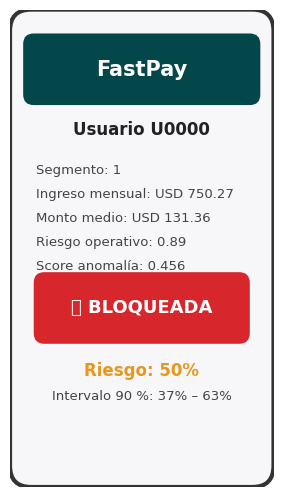

In [43]:
# ✏️ Pantalla de la app
idx_ej = perfil['riesgo_op'].idxmax()
u = df[df['cluster_kmeans'] == idx_ej].iloc[0]

score = (u['score_anomalia'] - df['score_anomalia'].min()) / \
        (df['score_anomalia'].max() - df['score_anomalia'].min())

curso.pantalla_resultado(
    NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA,
    f"Usuario {u['usuario_id']}",
    [
        f"Segmento: {idx_ej}",
        f"Ingreso mensual: USD {u['ingreso_mensual']:.2f}",
        f"Monto medio: USD {u['monto_medio']:.2f}",
        f"Riesgo operativo: {u['indice_riesgo_operativo']:.2f}",
        f"Score anomalía: {u['score_anomalia']:.3f}"
    ],
    probs=[1 - score, score]
)

---
## 6. Ficha del modelo (4 pts)
Ejecute y suba el archivo descargado a `proyecto/` en GitHub (**Add file → Upload files**).

In [44]:
ficha = curso.ficha_modelo(
    GRUPO, PROBLEMA,
    modelo='K-Means (segmentación) + Isolation Forest (anomalías)',
    metricas={
        'silueta_kmeans':       round(sil_kmeans, 4),
        'silueta_jerarquico':   round(sil_jerarquico, 4),
        'n_clusters':           int(k_optimo),
        'pct_anomalias':        round(pct_anom, 2),
        'fraudes_en_anomalos':  fraudes_en_anomalias
    },
    hiperparametros={
        'k_optimo': k_optimo,
        'random_state': 42,
        'n_init_kmeans': 50,
        'contamination_isolation_forest': 0.05,
        'eps_dbscan_percentil': 90,
        'min_samples_dbscan': 10
    }
)

{
  "grupo": "Grupo 6",
  "problema": "segmentacion",
  "modelo": "K-Means (segmentación) + Isolation Forest (anomalías)",
  "metricas": {
    "silueta_kmeans": 0.1879,
    "silueta_jerarquico": 0.201,
    "n_clusters": 8,
    "pct_anomalias": 5.03,
    "fraudes_en_anomalos": 27
  },
  "hiperparametros": {
    "k_optimo": 8,
    "random_state": 42,
    "n_init_kmeans": 50,
    "contamination_isolation_forest": 0.05,
    "eps_dbscan_percentil": 90,
    "min_samples_dbscan": 10
  },
  "semilla": 42,
  "semilla_datos": 365051,
  "fecha": "2026-11-17 03:57",
  "versiones": {
    "python": "3.13.18",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1"
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 7. Plantilla del informe (`proyecto/README.md`)
En GitHub abra `proyecto/README.md` → **lápiz (Edit)** → reemplace todo por este texto completado con sus cifras → **Commit changes**:

```
# Sistema de decisión para PagoYa — <Grupo>
Integrantes: ...   ·   Problema: ...

## 1. Problema y datos
## 2. Modelos comparados (tabla de métricas)
## 3. Qué explica el resultado (variables, segmentos, incertidumbre)
## 4. Recomendación con cifras
## 5. Limitaciones y próximos pasos
```